# Monotonic KAN Transport Maps for L-SING
### Collaborator companion to `theory/kan_transport.tex`

1. [Executive summary and transport](#1-executive-summary-and-transport)
2. [B-spline foundations](#2-b-spline-foundations)
3. [Performance and profiling](#3-performance-and-profiling)
4. [Gaussian graph recovery](#4-gaussian-graph-recovery-d10)
5. [Butterfly scale modulation](#5-butterfly-scale-modulation-d10)
6. [TCGA ovarian cancer](#6-tcga-ovarian-cancer-d156)
7. [Synthesis](#7-synthesis)

## 1. Executive summary and transport
L-SING learns one-dimensional conditional maps
$S^k(x_{-k},\cdot)_\sharp\pi(x_k\mid x_{-k})=\mathcal N(0,1)$.
The generalized precision matrix $\widehat\Omega_{jk}=\mathbb E[T_{jk}(X)]$ extracts conditional dependence, where
$$T_{jk}=-S_jS_k-SS_{jk}+\frac{S_{jkk}S_k-S_{kk}S_{jk}}{S_k^2}. $$
Positive-weight monotonic MLPs with convex activations face the **Archer–Wang convexity trap** ($f''\ge0$), whereas monotonic B-splines can change curvature. UMNN avoids this constraint but requires 50-node Clenshaw–Curtis quadrature per sample and third-order autodiff. Monotonic KAN replaces the integral with exact B-spline evaluation and analytic derivatives.

**Manuscript figures:** SM-KAN architecture (`theory/kan_transport.tex`, Definition of SM-KAN) and monotonic profiles.

Device: cpu; precomputed results: results/kan_benchmarks (root: /home/stefano/lsing_sw)


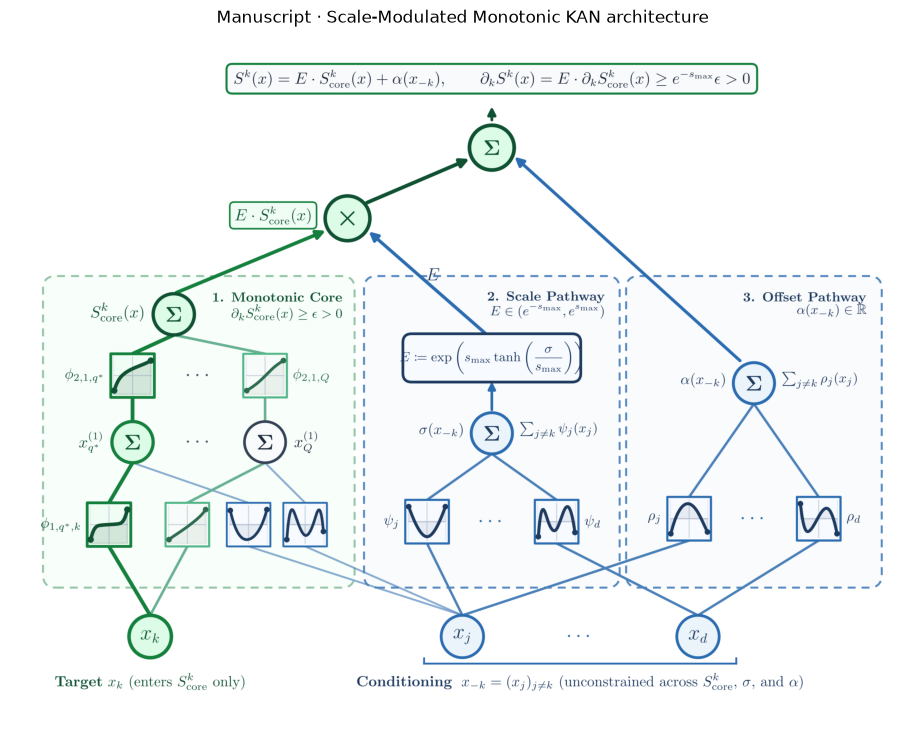

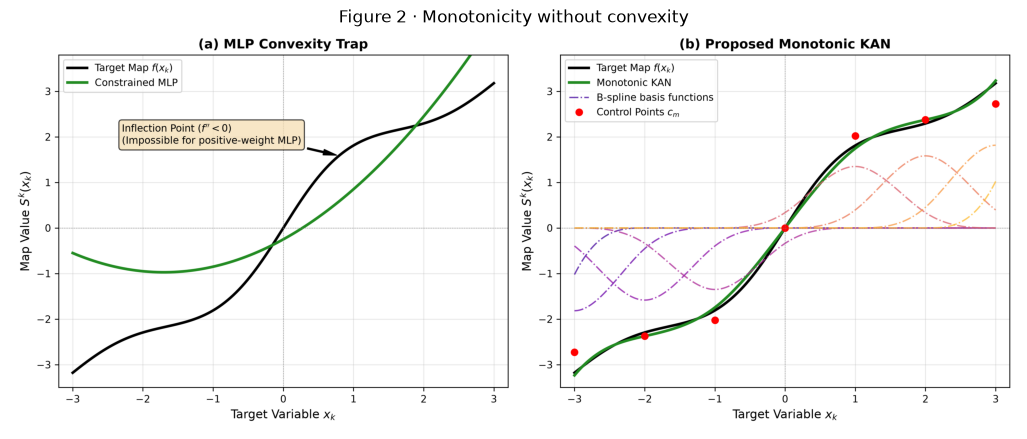

In [1]:
import os, sys, json, subprocess
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import display, Markdown

# Colab opens a GitHub notebook in /content, not in the repository checkout.
# Use the fork's current branch for the paper figures and committed results.
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
REPO_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents, Path("/content/lsing_sw"))
                  if (p / "theory/kan_transport.tex").is_file()), None)
if REPO_ROOT is None and IN_COLAB:
    REPO_ROOT = Path("/content/lsing_sw")
    if REPO_ROOT.exists():
        raise FileNotFoundError(f"Existing {REPO_ROOT} is not the expected repository; do not overwrite it")
    subprocess.run(["git", "clone", "--depth", "1", "--branch", "feat/monotonic-kan-transport",
                    "https://github.com/StefanoFochesatto/lsing_sw.git", str(REPO_ROOT)], check=True)
if REPO_ROOT is None:
    raise FileNotFoundError("Run from the repository root or notebooks/ directory (or open in Colab)")
REPO_ROOT = REPO_ROOT.resolve()
for path in (REPO_ROOT, REPO_ROOT / "src"):
    if str(path) not in sys.path: sys.path.insert(0, str(path))
RESULTS = REPO_ROOT / "results/kan_benchmarks"
RERUN_BENCHMARKS = False  # Presentation loads committed results; no training or quadrature.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}; precomputed results: results/kan_benchmarks (root: {REPO_ROOT})")

def paper_figure(name, caption, figsize=(13, 6)):
    path = REPO_ROOT / "theory/figures" / name
    if not path.is_file(): raise FileNotFoundError(path)
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(mpimg.imread(path)); ax.axis("off")
    ax.set_title(caption)
    plt.show(); plt.close(fig)

paper_figure("fig_sm_kan_liu.png", "Manuscript · Scale-Modulated Monotonic KAN architecture", figsize=(12, 9))
paper_figure("fig2_monotonic_profiles_and_convexity.png", "Figure 2 · Monotonicity without convexity")

## 2. B-spline foundations
**Lemma 4.1.** For a cubic spline $\phi(t)=\sum_m c_m B_{m,3}(t)$, de Boor differentiation gives a nonnegative quadratic-basis expansion in $c_{m+1}-c_m$. Choose
$$c_m=c_1+\sum_{r=1}^{m-1}(\operatorname{softplus}(\theta_r)+\delta_{\rm mono}).$$
This enforces positive interior slopes; $C^1$ linear extrapolation extends the boundary slopes to both tails. The following small, device-aware demonstration checks $[-8,8]$.

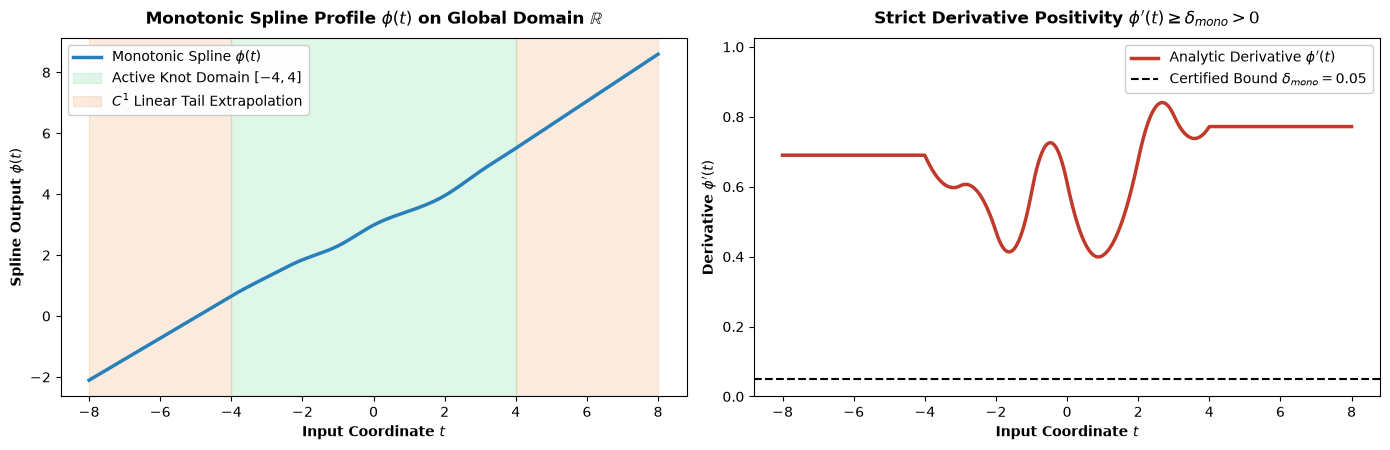

Lemma 4.1 Verification: Minimum spline derivative on [-8, 8] is 0.39922 > 0!


In [2]:
# Demonstration of Lemma 4.1: Cumulative Softplus & C^1 Linear Tail Extrapolation
from models.monotonic_kan import BSplineBasis

grid_min, grid_max = -4.0, 4.0
num_intervals = 8
spline_order = 3
grid = BSplineBasis.build_grid(grid_min, grid_max, num_intervals=num_intervals, degree=spline_order, device=device)
M = num_intervals + spline_order  # 11 control points
delta_mono = 0.05

# Random unconstrained parameters theta
torch.manual_seed(123)
theta = torch.randn(M, device=device)
c = torch.zeros(M, device=device)
c[0] = theta[0]
c[1:] = c[0] + torch.cumsum(torch.nn.functional.softplus(theta[1:]) + delta_mono, dim=0)

# Evaluate B-spline across interior and far extrapolation tails [-8, 8]
t_eval = torch.linspace(-8.0, 8.0, 1000, device=device).unsqueeze(1)
c_tensor = c.view(1, 1, M)

bases, d1, d2, d3 = BSplineBasis.eval_basis(t_eval, grid, spline_order)
phi = torch.sum(bases * c_tensor, dim=-1).squeeze().detach().cpu().numpy()
phi_p = torch.sum(d1 * c_tensor, dim=-1).squeeze().detach().cpu().numpy()
assert phi_p.min() >= delta_mono, "Spline monotonicity check failed"
t_cpu = t_eval.squeeze().detach().cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

# Panel 1: Profile phi(t)
axes[0].plot(t_cpu, phi, color="#2980b9", lw=2.5, label=r"Monotonic Spline $\phi(t)$")
axes[0].axvspan(grid_min, grid_max, color="#2ecc71", alpha=0.15, label="Active Knot Domain $[-4, 4]$")
axes[0].axvspan(-8, grid_min, color="#e67e22", alpha=0.15, label=r"$C^1$ Linear Tail Extrapolation")
axes[0].axvspan(grid_max, 8, color="#e67e22", alpha=0.15)
axes[0].set_title(r"Monotonic Spline Profile $\phi(t)$ on Global Domain $\mathbb{R}$", fontweight="bold", pad=10)
axes[0].set_xlabel("Input Coordinate $t$", fontweight="bold")
axes[0].set_ylabel(r"Spline Output $\phi(t)$", fontweight="bold")
axes[0].legend(loc="upper left", framealpha=0.95)

# Panel 2: Derivative phi'(t)
axes[1].plot(t_cpu, phi_p, color="#c0392b", lw=2.5, label=r"Analytic Derivative $\phi'(t)$")
axes[1].axhline(delta_mono, color="black", linestyle="--", label=rf"Certified Bound $\delta_{{mono}} = {delta_mono}$")
axes[1].set_title(r"Strict Derivative Positivity $\phi'(t) \geq \delta_{mono} > 0$", fontweight="bold", pad=10)
axes[1].set_xlabel("Input Coordinate $t$", fontweight="bold")
axes[1].set_ylabel(r"Derivative $\phi'(t)$", fontweight="bold")
axes[1].set_ylim(0, max(phi_p) * 1.22)
axes[1].legend(loc="upper right", framealpha=0.95)

plt.tight_layout()
plt.show()
print(f"Lemma 4.1 Verification: Minimum spline derivative on [-8, 8] is {phi_p.min():.5f} > 0!")

The transport pushforward is illustrated by the manuscript’s Figure 4 (target conditional → $S^k$ → standard normal).

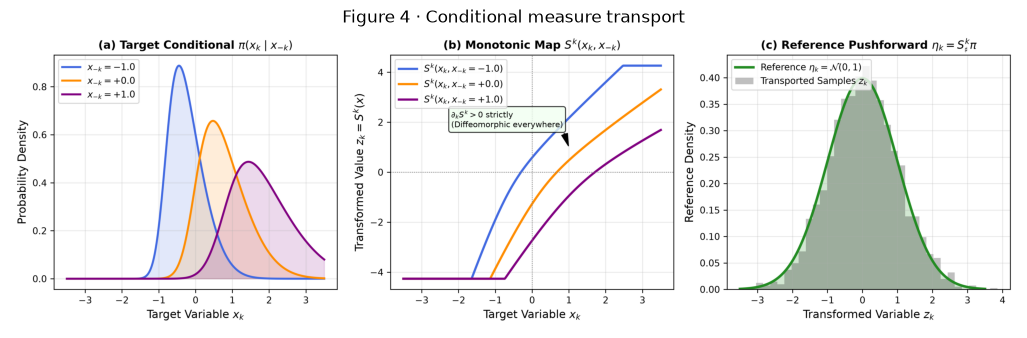

In [3]:
paper_figure("fig4_measure_transport_pushforward.png", "Figure 4 · Conditional measure transport")

## 3. Performance and profiling
**Published CPU measurements** from `kan_benchmark_results.md` §2 (not live device timings). The display works on CUDA and CPU alike because it loads results rather than allocating large autodiff graphs. At $N=1{,}000$, KAN takes 0.059 s versus 5.898 s for UMNN (100.5×); at $N=2{,}000$, 0.127 s versus 10.558 s (83.1×). Analytic Einstein recurrence is 110.8× faster than `torch.func.hessian` vmap and builds no computation graph (0 MB graph memory).

| Published CPU metric | UMNN | KAN | Advantage |
|---|---:|---:|---:|
| Parameters / feature | 1,523 | 485 | 3.14× compact |
| Training samples/s | 33,011 | 104,591 | 3.17× |
| Precision extraction N=1,000 (s) | 5.898 | 0.059 | 100.5× |
| Precision extraction N=2,000 (s) | 10.558 | 0.127 | 83.1× |
| KAN analytic vs. torch.func.hessian vmap | — | 0.059 vs. 6.504 s | 110.8×; 0 MB graph memory |

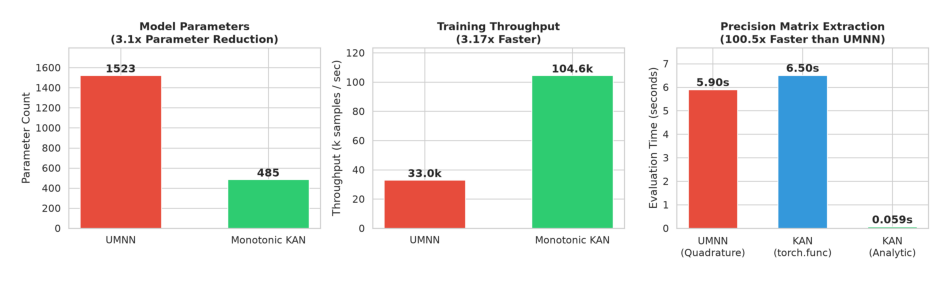

In [4]:
with (RESULTS / "profiling.json").open() as f: profiling = json.load(f)
params = profiling["parameter_count"]
throughput = profiling["training_throughput"]
latency = profiling["precision_matrix_extraction"]
display(Markdown(f'''| Published CPU metric | UMNN | KAN | Advantage |
|---|---:|---:|---:|
| Parameters / feature | {params["umnn"]:,} | {params["monotonic_kan"]:,} | 3.14× compact |
| Training samples/s | {throughput["umnn_samples_per_sec"]:,.0f} | {throughput["kan_samples_per_sec"]:,.0f} | 3.17× |
| Precision extraction N=1,000 (s) | {latency["umnn_quadrature_seconds"]:.3f} | {latency["kan_analytic_chain_seconds"]:.3f} | 100.5× |
| Precision extraction N=2,000 (s) | 10.558 | 0.127 | 83.1× |
| KAN analytic vs. torch.func.hessian vmap | — | 0.059 vs. 6.504 s | 110.8×; 0 MB graph memory |'''))
# Render the committed publication-aligned chart; do not run hardware-specific timing here.
chart = RESULTS / "figures/chart_computational_speedup.png"
fig, ax = plt.subplots(figsize=(12, 5)); ax.imshow(mpimg.imread(chart)); ax.axis("off")
plt.show(); plt.close(fig)

## 4. Gaussian graph recovery ($d=10$)
The true $\Omega=\Sigma^{-1}$ has four edges $(0,4),(2,6),(5,7),(6,9)$. At $\tau=0.20$ both methods have $F_1=1.000$, FPR = 0.000. At $\tau=0.10$ UMNN falls to $F_1=0.667$ (4 false positives; FPR = 0.098), while monotonic KAN retains $F_1=1.000$, FPR = 0.000. This is the tail-noise suppression result, not a new topology illustration.

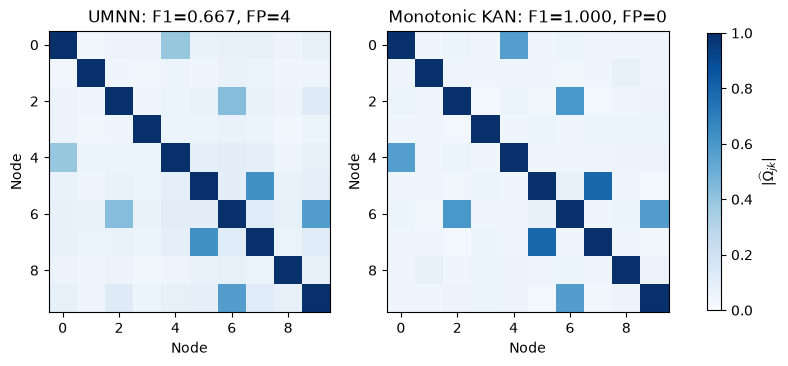

In [5]:
with (RESULTS / "gaussian_benchmark.json").open() as f: gaussian = json.load(f)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, key, title in zip(axes, ("UMNN", "MonotonicKAN_Functional"), ("UMNN", "Monotonic KAN")):
    matrix = np.abs(np.asarray(gaussian[key]["precision_matrix"]))
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"{title}: F1={gaussian[key]['metrics']['0.1']['f1']:.3f}, FP={gaussian[key]['metrics']['0.1']['fp']}")
    ax.set_xlabel("Node"); ax.set_ylabel("Node")
fig.colorbar(image, ax=axes, label=r"$|\widehat{\Omega}_{jk}|$", shrink=.8)
plt.show(); plt.close(fig)

## 5. Butterfly scale modulation ($d=10$)
Five independent pairs satisfy $X\sim\mathcal N(0,1)$, $Y=WX$, so $\operatorname{Var}(Y\mid X)=X^2$.

**Figure 5:** (a) bow-tie distribution; (b) ideal conditional transport $S^Y(Y;X)=Y/|X|$ for $X\in\{0.5,1,2\}$ (undefined at $X=0$, a null event); (c) isotropic $(Z_X,Z_Y)\sim\mathcal N(0,I_2)$; (d) SM-KAN precision with five connected pairs. The weakest true edge is 0.415 and strongest non-edge 0.112: $\Delta=0.303$, $F_1=1.000$, FPR = 0 across $\tau\in[0.15,0.40]$ ($M=5{,}000$). At $d=40$ (20 pairs, 780 candidate edges), full precision extraction takes **0.68 s**, versus projected UMNN **203.6 s** (299×).

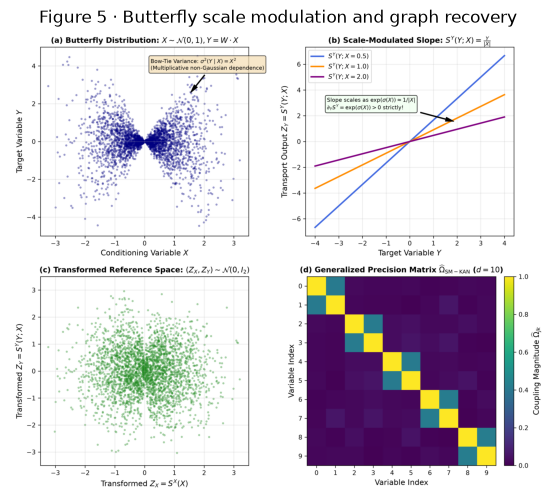

In [6]:
paper_figure("fig5_butterfly_scale_modulation.png", "Figure 5 · Butterfly scale modulation and graph recovery")

## 6. TCGA ovarian cancer ($d=156$)
The manuscript reports $N=578$ patients (346 train, 115 validation, 117 test), $\binom{156}{2}=12{,}090$ interactions and **1.99 s** for the full SM-KAN precision matrix. The projected UMNN full-network time is ≈42 minutes (>1,200×); an alternate 260.1 s UMNN baseline versus 7.5 s KAN corresponds to ≈35×. These are different protocols, **not** the committed 12-gene quick-run timing.

The committed `ovarian_precision_matrix_full.txt` is the full $156\times156$ published matrix, copied from the repository's original full-run artifact without modifying the local 12-gene quick-run file. The heatmap and density curve below use **only** that full matrix. CTSE and EPCAM are candidate hubs in the sparse regime ($\tau=0.08,0.10$); the separate 12-gene quick-run rank concordance is Spearman $\rho=0.282$, not validation of clinical utility.

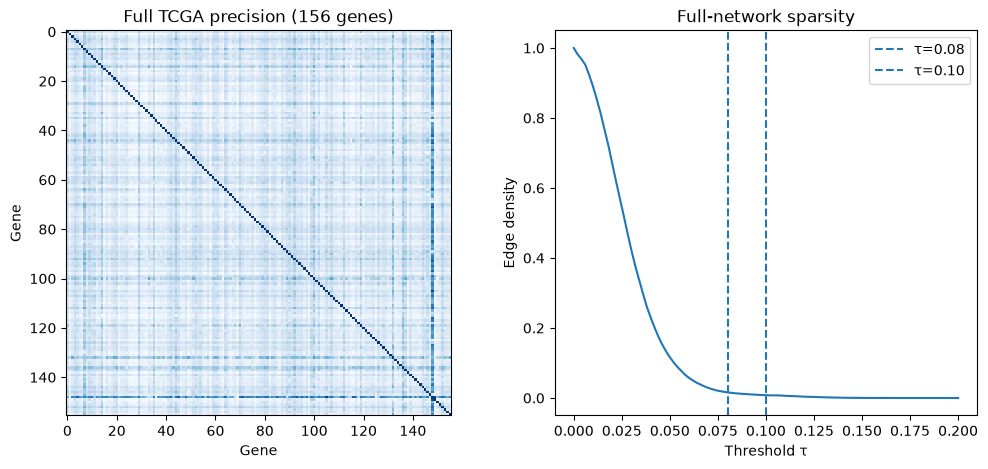

Separate 12-gene quick-run rank concordance: Spearman ρ=0.282


In [7]:
matrix_path = RESULTS / "ovarian_precision_matrix_full.txt"
matrix = np.loadtxt(matrix_path, delimiter=",")
if matrix.shape != (156, 156):
    raise ValueError(f"Expected a published 156x156 matrix, got {matrix.shape}")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(np.abs(matrix), cmap="Blues", interpolation="nearest", vmin=0, vmax=.18)
axes[0].set(title="Full TCGA precision (156 genes)", xlabel="Gene", ylabel="Gene")
thresholds = np.linspace(0, .2, 101)
upper = np.abs(matrix[np.triu_indices(156, 1)])
axes[1].plot(thresholds, [(upper > t).mean() for t in thresholds])
for cutoff in (.08, .10):
    axes[1].axvline(cutoff, linestyle="--", label=f"τ={cutoff:.2f}")
axes[1].set(xlabel="Threshold τ", ylabel="Edge density", title="Full-network sparsity")
axes[1].legend()
plt.show(); plt.close(fig)
with (RESULTS / "ovarian_results.json").open() as f:
    ovarian_results = json.load(f)
if ovarian_results.get("num_genes") == 12 and "comparison" in ovarian_results:
    print(f"Separate 12-gene quick-run rank concordance: Spearman ρ={ovarian_results['comparison']['spearman_correlation']:.3f}")
else:
    print("Displayed full-run matrix; quick-run Spearman concordance (ρ=0.282) is from a separate protocol.")

## 7. Synthesis
| Metric / property | UMNN baseline | Scale-Modulated KAN | Advantage |
|:---|---:|---:|:---|
| Numerical quadrature | 50 nodes/sample | None | Exact forward pass |
| Precision evaluation $d=10$ | 10.56 s | **0.14 s** | **84×** |
| Precision evaluation $d=40$ | 203.6 s (projected) | **0.68 s** | **299×** |
| Precision evaluation $d=156$ ovarian | ≈42 min (projected) | **1.99 s** | **>1,200×** |
| Peak memory $d=10$ | 71.1 MB | **0.25 MB** | **284× lower** |
| Parameters per feature | 1,523 | **485** | **3.14× compact** |
| Training throughput | 33,011 samples/s | **104,591 samples/s** | **3.17×** |
| Gaussian $F_1$ at $\tau=0.10$ | 0.667 (4 FP) | **1.000 (0 FP)** | Perfect recovery |
| Butterfly $F_1$ at $M=5{,}000$ | 1.000 | **1.000** | Resolves heteroscedasticity |

**Three takeaways.** (1) Closed-form B-spline forward evaluation and `torch.einsum` recurrences compute first–third derivatives without quadrature. (2) Cumulative-softplus control points preserve $\partial_k S^k>0$ while allowing $\phi''$ to change sign. (3) $S^k(x)=\exp(\sigma(x_{-k}))S^k_{\rm core}(x)+\alpha(x_{-k})$ decouples location and scale for multiplicative non-Gaussian dependence.

**Discussion:** Published times are CPU measurements from different benchmark configurations; projections are marked explicitly. Ovarian heatmap and edge-density curve are computed from the committed full-run artifact, not the separate 12-gene quick run.